# Rossman Sales Forecasting

### Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Loading The Dataset

In [3]:
df = pd.read_csv("Rossman_store.csv")

C:\Users\kashr\AppData\Local\Temp\ipykernel_15180\2326356240.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Rossman_store.csv")


In [4]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
df.tail()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1
1017208,1115,2,2013-01-01,0,0,0,0,a,1


In [6]:
df.shape

(1017209, 9)

# Understanding The Data

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 79.5+ MB


In [21]:
print(df.columns.tolist())

['Store', 'DayOfWeek', 'date', 'Sales', 'Customers', 'Open', 'Promo', 'int64', 'SchoolHoliday']


In [28]:
df["date"] = pd.to_datetime(df["date"])

df.rename(columns={"int64": "StateHoliday"}, inplace=True)

df["StateHoliday"] = df["StateHoliday"].astype("category")

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  category      
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: category(1), datetime64[us](1), int64(7)
memory usage: 63.1 MB


In [30]:
df.describe()

,Store,DayOfWeek,date,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1017209,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,2014-04-11 01:30:42.846062,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
min,1.000000e+00,1.000000e+00,2013-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,2013-08-17 00:00:00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,2014-04-02 00:00:00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,2014-12-12 00:00:00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,2015-07-31 00:00:00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00
std,3.219087e+02,1.997391e+00,NaN,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01


In [31]:
df["StateHoliday"].value_counts()

StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64

In [32]:
df.isnull().sum()

Store            0
DayOfWeek        0
date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [33]:
df.duplicated()

0          False
1          False
2          False
3          False
4          False
           ...  
1017204    False
1017205    False
1017206    False
1017207    False
1017208    False
Length: 1017209, dtype: bool

## Checking the Data Column

In [38]:
df["date"] = pd.to_datetime(df["date"])

In [42]:
df["date"].min()
df["date"].max()

Timestamp('2015-07-31 00:00:00')

In [43]:
df["date"].min()

Timestamp('2013-01-01 00:00:00')

In [44]:
df["date"].max()

Timestamp('2015-07-31 00:00:00')

In [45]:
df["date"].nunique()

942

## Checking The Stores

In [46]:
df["Store"].nunique()

1115

In [62]:
print(df["Store"].value_counts().sort_index())

Store
1       942
2       942
3       942
4       942
5       942
       ... 
1111    942
1112    942
1113    942
1114    942
1115    942
Name: count, Length: 1115, dtype: int64


In [80]:
store_800 = df[df["Store"] == 800].copy()

store_800 = store_800.sort_values("date")

store_800 = store_800.set_index("date")

sales = store_800["Sales"]

In [70]:
df[df["Store"] == 800].shape

(942, 9)

In [69]:
store_800.shape

(942, 8)

In [71]:
print("First date:", store_800.index.min())
print("Last date:", store_800.index.max())

First date: 2013-01-01 00:00:00
Last date: 2015-07-31 00:00:00


In [72]:
print("Number of dates:", len(store_800.index))

print(
    "Number of unique dates:",
    store_800.index.nunique()
)

Number of dates: 942
Number of unique dates: 942


In [77]:
expected_dates = pd.date_range(
    start=store_800.index.min(),
    end=store_800.index.max(),
    freq="D"
)

missing_dates = expected_dates.difference(store_800.index)

print("Expected daily dates:", len(expected_dates))
print("Missing dates:", len(missing_dates))
print(missing_dates[:10])

Expected daily dates: 942
Missing dates: 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')


In [74]:
store_800["Open"].value_counts()

Open
1    779
0    163
Name: count, dtype: int64

In [75]:
store_800.groupby("Open")["Sales"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Open,,,,
0,163,0.000000,0,0
1,779,5337.432606,1995,12368


## Exploratory Data Analysis

In [81]:
sales.describe()

count      942.000000
mean      4413.864119
std       2373.284290
min          0.000000
25%       3673.750000
50%       4850.000000
75%       5918.000000
max      12368.000000
Name: Sales, dtype: float64

In [109]:
df.isnull().sum()

Store            0
DayOfWeek        0
date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [110]:
store_800.isnull().sum()

Store            0
DayOfWeek        0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
Weekday          0
dtype: int64

In [111]:
store_800.duplicated().sum()

np.int64(147)

In [112]:

duplicates = store_800[store_800.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))

duplicates.head(10)


Rows involved in duplicates: 155


,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Weekday
date,,,,,,,,,
2013-01-06,800,7,0,0,0,0,0,0,Sunday
2013-01-13,800,7,0,0,0,0,0,0,Sunday
2013-01-20,800,7,0,0,0,0,0,0,Sunday
2013-01-27,800,7,0,0,0,0,0,0,Sunday
2013-02-03,800,7,0,0,0,0,0,0,Sunday
2013-02-10,800,7,0,0,0,0,0,0,Sunday
2013-02-17,800,7,0,0,0,0,0,0,Sunday
2013-02-24,800,7,0,0,0,0,0,0,Sunday
2013-03-03,800,7,0,0,0,0,0,0,Sunday


In [113]:
print("Total rows:", len(store_800))
print("Unique dates:", store_800.index.nunique())
print("Repeated dates:", store_800.index.duplicated().sum())


Total rows: 942
Unique dates: 942
Repeated dates: 0


### Distribution of Daily sales

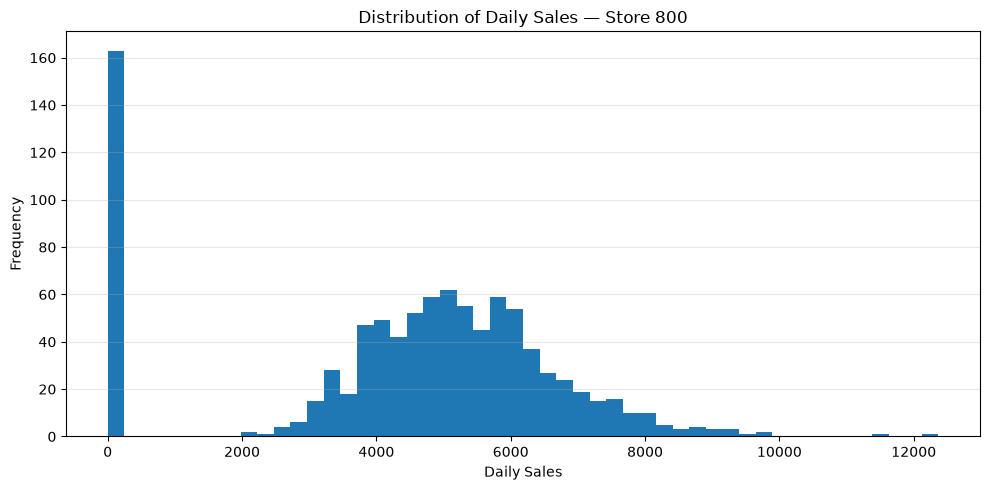

In [86]:
import matplotlib.pyplot as plt

sales.plot(kind="hist", bins=50, figsize=(10, 5))

plt.title("Distribution of Daily Sales — Store 800")
plt.xlabel("Daily Sales")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [87]:
Q1 = sales.quantile(0.25)
Q3 = sales.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

Q1: 3673.75
Q3: 5918.0
IQR: 2244.25
Lower boundary: 307.375
Upper boundary: 9284.375


In [88]:
outliers = sales[
    (sales < lower_bound) | (sales > upper_bound)
]

print("Total potential outliers:", len(outliers))
print("Potential low outliers:", (sales < lower_bound).sum())
print("Potential high outliers:", (sales > upper_bound).sum())

Total potential outliers: 168
Potential low outliers: 163
Potential high outliers: 5


In [89]:
low_outliers = store_800[
    store_800["Sales"] < lower_bound
]

low_outliers.groupby("Open")["Sales"].agg(
    ["count", "min", "max", "mean"]
)

,count,min,max,mean
Open,,,,
0,163,0,0,0.0


In [90]:
high_outliers = store_800[
    store_800["Sales"] > upper_bound
].sort_values("Sales", ascending=False)

high_outliers[
    ["Sales", "Customers", "Open", "Promo"]
]

,Sales,Customers,Open,Promo
date,,,,
2013-12-23,12368,1106,1,0
2013-12-16,11489,904,1,1
2013-12-19,9774,829,1,1
2013-12-20,9764,815,1,1
2013-12-17,9549,722,1,1


In [96]:

# Calculate average sales for each day of the week
weekday_sales = (
    store_800.groupby("DayOfWeek")["Sales"]
    .mean()
    .reindex([1, 2, 3, 4, 5, 6, 7])
)

# Replace numbers with weekday names
weekday_sales.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

print(weekday_sales.round(2))


Monday       5832.57
Tuesday      5010.34
Wednesday    4894.72
Thursday     4778.38
Friday       5205.25
Saturday     5159.13
Sunday          0.00
Name: Sales, dtype: float64


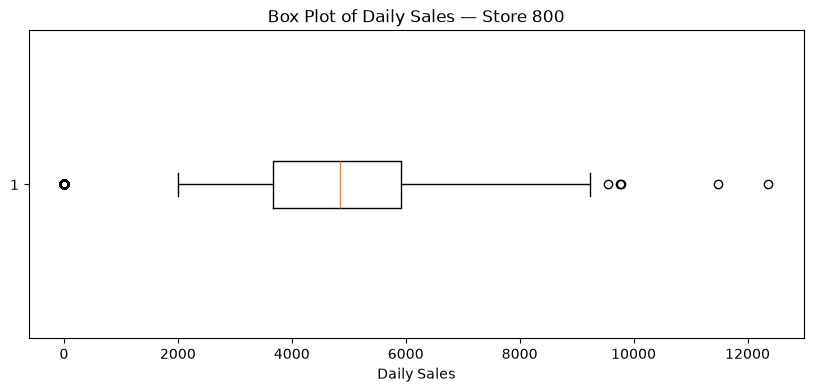

In [98]:
plt.figure(figsize=(10, 4))

plt.boxplot(sales, orientation="horizontal")

plt.title("Box Plot of Daily Sales — Store 800")
plt.xlabel("Daily Sales")

plt.show()


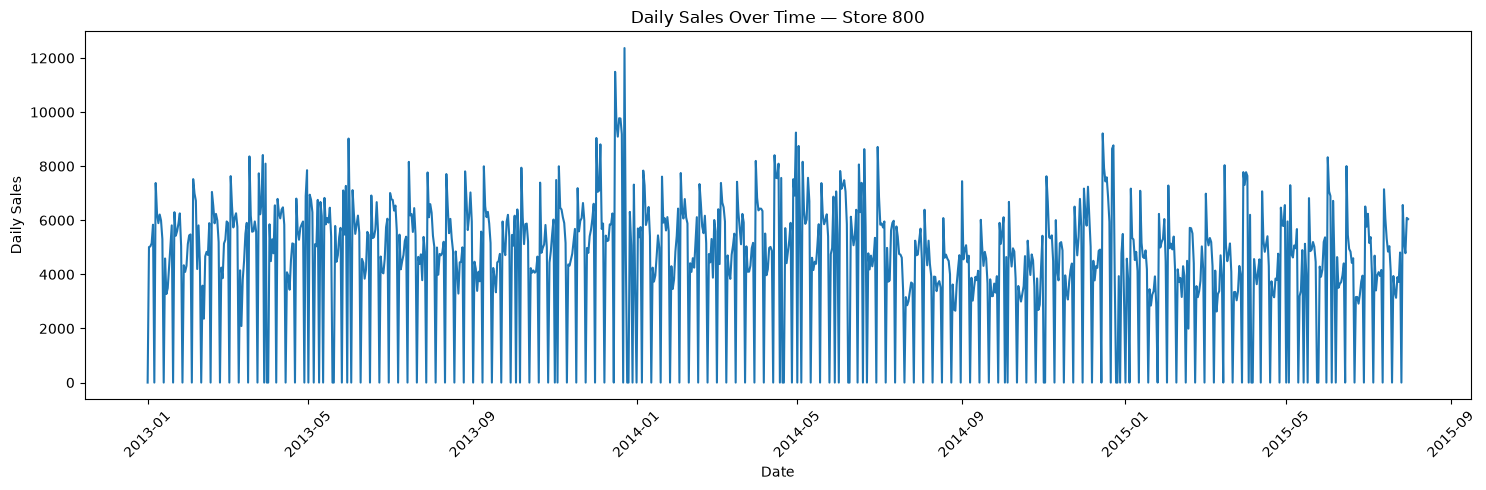

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(sales.index, sales.values)

plt.title("Daily Sales Over Time — Store 800")
plt.xlabel("Date")
plt.ylabel("Daily Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [100]:
store_800.groupby("Promo", observed=True)["Sales"].mean()


Promo
0    3427.264605
1    6008.866667
Name: Sales, dtype: float64

In [101]:
# Compare average sales on open days only
open_store = store_800[store_800["Open"] == 1]

promo_sales_open = (
    open_store.groupby("Promo", observed=True)["Sales"].mean()
)

print(promo_sales_open.round(2))


Promo
0    4649.58
1    6180.55
Name: Sales, dtype: float64


In [103]:
store_800.groupby("Open", observed=True)["Sales"].mean()


Open
0       0.000000
1    5337.432606
Name: Sales, dtype: float64

In [104]:
store_800.groupby("StateHoliday", observed=True)["Sales"].mean()



StateHoliday
0    4172.364341
0    4616.868622
a       0.000000
b       0.000000
c       0.000000
Name: Sales, dtype: float64

In [105]:
print(store_800["StateHoliday"].value_counts(dropna=False).to_dict())

print("\nData type of each category value:")
print(store_800["StateHoliday"].map(type).value_counts())


{'0': 784, 0: 129, 'a': 19, 'b': 6, 'c': 4}

Data type of each category value:
StateHoliday
<class 'str'>    813
<class 'int'>    129
Name: count, dtype: int64


In [106]:
# Convert all holiday values to strings
store_800["StateHoliday"] = (
    store_800["StateHoliday"].astype(str).str.strip()
)

# Convert the column to a category
store_800["StateHoliday"] = (
    store_800["StateHoliday"].astype("category")
)

# Check the cleaned categories
print(store_800["StateHoliday"].value_counts())


StateHoliday
0    913
a     19
b      6
c      4
Name: count, dtype: int64


In [107]:
store_800.groupby(
    "StateHoliday", observed=True
)["Sales"].mean().round(2)


StateHoliday
0    4554.06
a       0.00
b       0.00
c       0.00
Name: Sales, dtype: float64

For Store 800, average recorded sales were 4,554.06 on days without a state holiday, while the recorded average was zero for each holiday category.

In [108]:
store_800.groupby("SchoolHoliday", observed=True)["Sales"].mean().round(2)

SchoolHoliday
0    4318.66
1    4916.53
Name: Sales, dtype: float64

Average recorded sales were 4,318.66 on days without a school holiday and 4,916.53 on school-holiday days. This indicates higher average sales on school-holiday days in the selected store's dataset. However, the comparison is descriptive and does not establish causation.

# Exploratory Data Analysis Report: Rossmann Store 800

## 1. Introduction

This analysis explores daily sales data for Rossmann Store 800 as part of a time-series forecasting project. The objective is to understand the sales distribution, identify potential outliers, examine patterns over time, and investigate relationships between sales and selected business factors.

## 2. Data Preparation

The original dataset contains 1,017,209 records across nine columns. Store 800 was selected for individual analysis, providing 942 daily records spanning 1 January 2013 to 31 July 2015. 

### Data Quality and Repeated-Row Check

Store 800 contains 942 records across nine columns, covering 1 January 2013 to 31 July 2015. All nine columns have zero missing values. The date column was converted to datetime format, and `StateHoliday` values were standardised to resolve inconsistent representations of zero. The dataset contains 942 unique dates, with no repeated dates. Although some rows may have identical values across columns, identical values on different dates do not necessarily indicate duplicate records, particularly on store-closure days. Therefore, records were not removed solely because their values matched.

## 3. Sales Distribution and Outliers

Descriptive statistics for Store 800 showed average daily sales of 4,413.86, a median of 4,850, and a maximum of 12,368. A histogram and box plot were used to examine the distribution and identify potential outliers.

The IQR method identified 168 potential outliers: 163 low outliers and five high outliers. Investigation showed that all 163 low outliers corresponded to zero sales on days when the store was closed. The five high outliers occurred on open days, with four associated with promotions. These observations were not automatically removed.

## 4. Sales Patterns Over Time

A line chart of daily sales showed repeated increases and decreases over the observation period. This indicates fluctuations in daily sales. Further decomposition and forecasting analysis will be conducted separately.

## 5. Weekday Sales Analysis

Average recorded sales varied by weekday. Monday had the highest average at 5,832.57 among the seven weekdays, while Sunday had an average of zero. The zero Sunday average is consistent with closure days in the dataset, although opening patterns should be considered when interpreting weekday comparisons.

## 6. Promotion Analysis

On all recorded days, average sales were 3,427.26 without promotions and 6,008.87 with promotions. Restricting the comparison to open days produced averages of 4,649.58 without promotions and 6,180.55 with promotions, a difference of approximately 32.9%.

This descriptive association suggests that promotional days were associated with higher average sales. However, the analysis does not establish that promotions caused the difference.

## 7. Store Opening Status

Average recorded sales were zero on closed days and 5,337.43 on open days. This demonstrates the importance of considering operating status when interpreting sales and identifying outliers.

## 8. State Holiday Analysis

After standardising the holiday categories, the analysis found average sales of 4,554.06 on days without a state holiday. Recorded average sales were zero for categories `a`, `b`, and `c`. These categories contained relatively few observations, and store closures may explain the zero averages. The results should therefore be interpreted cautiously.

## 9. School Holiday Analysis

Average recorded sales were 4,318.66 on days without a school holiday and 4,916.53 on school-holiday days. This represents an approximate difference of 13.8%. The result describes an observed association and does not establish causation.


## 10. Conclusion

The EDA of Store 800 identified variation in daily sales, differences across weekdays, higher average sales on promotional and school-holiday days, and a clear relationship between store closure and zero recorded sales. The investigation also showed that potential outliers should be examined in their business context before any removal or transformation.

These findings provide useful context for the next stage of the project. Time-series decomposition, baseline forecasting, and model evaluation will be addressed separately.